Training Model di Google Colab

In [1]:
# Install library yang dibutuhkan
!pip install pandas numpy scikit-learn joblib

# Mount Google Drive untuk menyimpan model
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Load dan Preprocessing Data

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib
import seaborn as sns
import matplotlib.pyplot as plt

# Upload file heart.csv ke Colab (gunakan upload button di sidebar)
# Atau upload dari local
from google.colab import files
uploaded = files.upload()

# Load data
df = pd.read_csv('heart.csv', sep=';')
print("Shape dataset:", df.shape)
print("\n5 data pertama:")
print(df.head())
print("\nInfo dataset:")
print(df.info())
print("\nStatistik deskriptif:")
print(df.describe())

Saving heart.csv to heart (1).csv
Shape dataset: (918, 12)

5 data pertama:
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  

Info dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column

Exploratory Data Analysis (EDA)


Missing values:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Distribusi HeartDisease:
HeartDisease
1    508
0    410
Name: count, dtype: int64
Persentase: HeartDisease
1    55.337691
0    44.662309
Name: proportion, dtype: float64


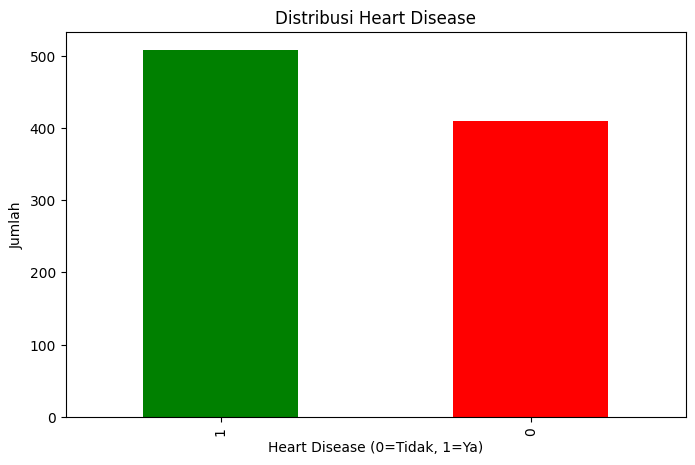

In [3]:
# Cek missing values
print("\nMissing values:")
print(df.isnull().sum())

# Cek distribusi target
print("\nDistribusi HeartDisease:")
print(df['HeartDisease'].value_counts())
print(f"Persentase: {df['HeartDisease'].value_counts(normalize=True) * 100}")

# Visualisasi target
plt.figure(figsize=(8,5))
df['HeartDisease'].value_counts().plot(kind='bar', color=['green', 'red'])
plt.title('Distribusi Heart Disease')
plt.xlabel('Heart Disease (0=Tidak, 1=Ya)')
plt.ylabel('Jumlah')
plt.show()

Preprocessing Fitur

In [4]:
# Pisahkan fitur dan target
X = df.drop('HeartDisease', axis=1)
y = df['HeartDisease']

# Identifikasi kolom kategorikal dan numerik
categorical_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
numerical_cols = ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']

print("Kolom kategorikal:", categorical_cols)
print("Kolom numerik:", numerical_cols)

# Encode kolom kategorikal
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])
    label_encoders[col] = le
    print(f"{col}: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# Feature Scaling untuk kolom numerik
scaler = StandardScaler()
X[numerical_cols] = scaler.fit_transform(X[numerical_cols])

print("\nData setelah preprocessing:")
print(X.head())

Kolom kategorikal: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
Kolom numerik: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']
Sex: {'F': np.int64(0), 'M': np.int64(1)}
ChestPainType: {'ASY': np.int64(0), 'ATA': np.int64(1), 'NAP': np.int64(2), 'TA': np.int64(3)}
RestingECG: {'LVH': np.int64(0), 'Normal': np.int64(1), 'ST': np.int64(2)}
ExerciseAngina: {'N': np.int64(0), 'Y': np.int64(1)}
ST_Slope: {'Down': np.int64(0), 'Flat': np.int64(1), 'Up': np.int64(2)}

Data setelah preprocessing:
        Age  Sex  ChestPainType  RestingBP  Cholesterol  FastingBS  \
0 -1.433140    1              1   0.410909     0.825070  -0.551341   
1 -0.478484    0              2   1.491752    -0.171961  -0.551341   
2 -1.751359    1              1  -0.129513     0.770188  -0.551341   
3 -0.584556    0              0   0.302825     0.139040  -0.551341   
4  0.051881    1              2   0.951331    -0.034755  -0.551341   

   RestingECG     MaxHR  ExerciseAngina  

Split Data

In [5]:
# Split data training dan testing (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")
print(f"Proporsi target di training:\n{y_train.value_counts(normalize=True)}")

Training set size: 734 samples
Testing set size: 184 samples
Proporsi target di training:
HeartDisease
1    0.553134
0    0.446866
Name: proportion, dtype: float64


Training Model Random Forest

In [6]:
from sklearn.model_selection import GridSearchCV

# Definisikan model
rf = RandomForestClassifier(random_state=42)

# Parameter grid untuk tuning
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Grid Search dengan cross-validation
grid_search = GridSearchCV(
    rf,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

print("Melakukan hyperparameter tuning...")
grid_search.fit(X_train, y_train)

print(f"\nBest parameters: {grid_search.best_params_}")
print(f"Best cross-validation score: {grid_search.best_score_:.4f}")

# Gunakan model terbaik
best_rf = grid_search.best_estimator_

Melakukan hyperparameter tuning...
Fitting 5 folds for each of 108 candidates, totalling 540 fits

Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 100}
Best cross-validation score: 0.8678


Evaluasi Model


Akurasi pada data test: 0.8804 (88.04%)

Classification Report:
               precision    recall  f1-score   support

   No Disease       0.89      0.83      0.86        82
Heart Disease       0.87      0.92      0.90       102

     accuracy                           0.88       184
    macro avg       0.88      0.88      0.88       184
 weighted avg       0.88      0.88      0.88       184


Confusion Matrix:
[[68 14]
 [ 8 94]]


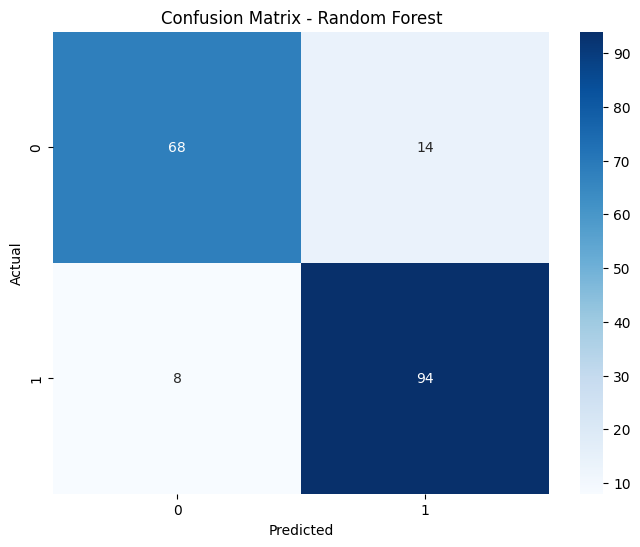


Feature Importance:
           feature  importance
10        ST_Slope    0.313056
2    ChestPainType    0.121424
9          Oldpeak    0.106547
4      Cholesterol    0.099882
8   ExerciseAngina    0.098706
7            MaxHR    0.090948
0              Age    0.056411
3        RestingBP    0.047472
1              Sex    0.030372
5        FastingBS    0.019936
6       RestingECG    0.015247


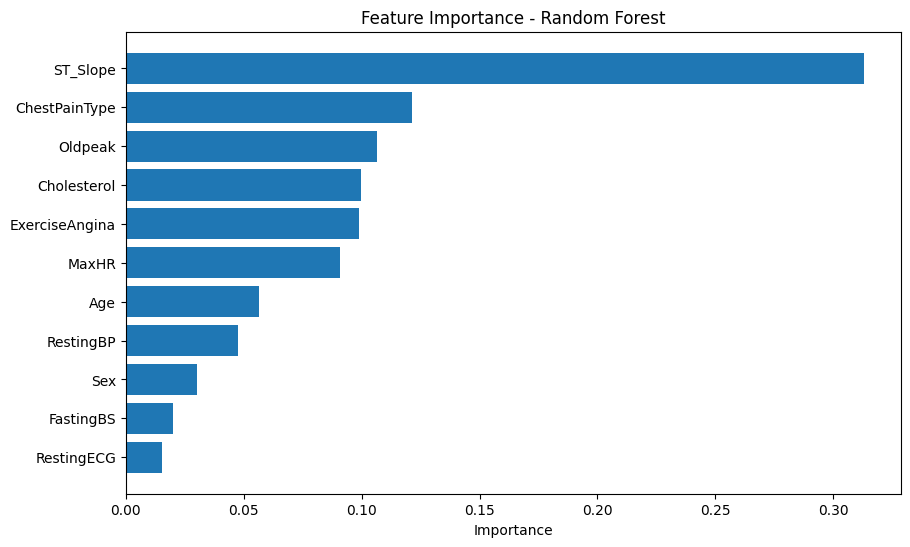

In [7]:
# Prediksi pada data test
y_pred = best_rf.predict(X_test)

# Hitung akurasi
accuracy = accuracy_score(y_test, y_pred)
print(f"\nAkurasi pada data test: {accuracy:.4f} ({accuracy*100:.2f}%)")

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['No Disease', 'Heart Disease']))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

# Visualisasi Confusion Matrix
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Feature Importance
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': best_rf.feature_importances_
}).sort_values('importance', ascending=False)

print("\nFeature Importance:")
print(feature_importance)

# Visualisasi Feature Importance
plt.figure(figsize=(10,6))
plt.barh(feature_importance['feature'], feature_importance['importance'])
plt.xlabel('Importance')
plt.title('Feature Importance - Random Forest')
plt.gca().invert_yaxis()
plt.show()

Simpan Model dan Preprocessors

In [8]:
# Buat folder di Google Drive
import os
os.makedirs('/content/drive/MyDrive/heart_disease_model', exist_ok=True)

# Simpan model
joblib.dump(best_rf, '/content/drive/MyDrive/heart_disease_model/model.pkl')

# Simpan scaler
joblib.dump(scaler, '/content/drive/MyDrive/heart_disease_model/scaler.pkl')

# Simpan label encoders
joblib.dump(label_encoders, '/content/drive/MyDrive/heart_disease_model/label_encoders.pkl')

# Simpan nama fitur
joblib.dump(X.columns.tolist(), '/content/drive/MyDrive/heart_disease_model/feature_names.pkl')

# Download model ke local (untuk web app)
files.download('/content/drive/MyDrive/heart_disease_model/model.pkl')
files.download('/content/drive/MyDrive/heart_disease_model/scaler.pkl')
files.download('/content/drive/MyDrive/heart_disease_model/label_encoders.pkl')
files.download('/content/drive/MyDrive/heart_disease_model/feature_names.pkl')

print("✅ Semua file model telah disimpan dan didownload!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Semua file model telah disimpan dan didownload!
